# Praktikum 1

In [1]:
# import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.preprocessing import StandardScaler

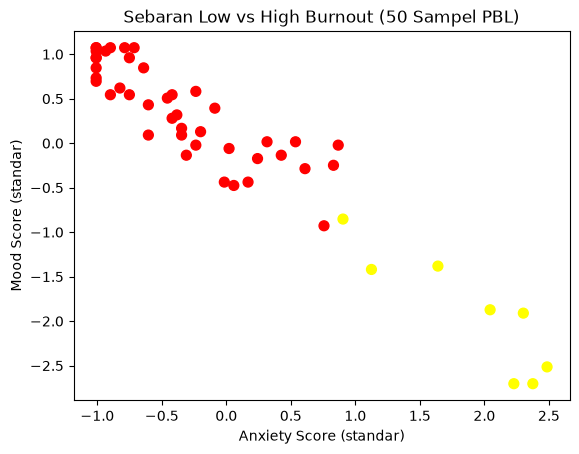

In [2]:
# Memuat Dataset PBL dan memilih dua fitur utama untuk visualisasi Linear SVM (Low vs High Burnout)
raw_df = pd.read_csv('burnout_dataset1.csv')
df_sub = raw_df[raw_df['Burnout_Risk'].isin(['Low', 'High'])][['Anxiety_Score', 'Mood_Score', 'Burnout_Risk']].dropna()
df_samp = df_sub.sample(n=50, random_state=42)

scaler = StandardScaler()
X = scaler.fit_transform(df_samp[['Anxiety_Score', 'Mood_Score']].to_numpy())
y = (df_samp['Burnout_Risk'] == 'High').astype(int).to_numpy()

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.xlabel('Anxiety Score (standar)')
plt.ylabel('Mood Score (standar)')
plt.title('Sebaran Low vs High Burnout (50 Sampel PBL)')
plt.show()

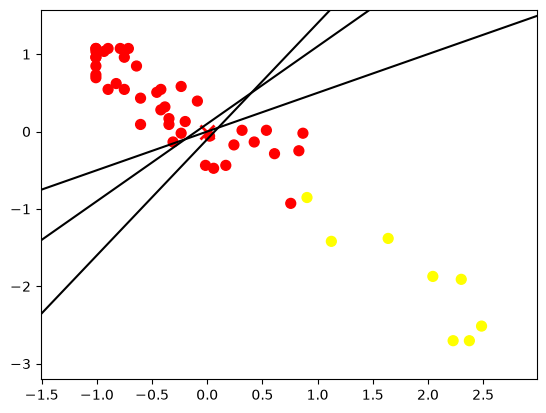

In [3]:
xfit = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot(0.0, 0.0, marker='x', color='red', markersize=10, markeredgewidth=2)

for m, b in [(0.5, 0.0), (1.0, 0.1), (1.5, -0.1)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
plt.ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
plt.show()

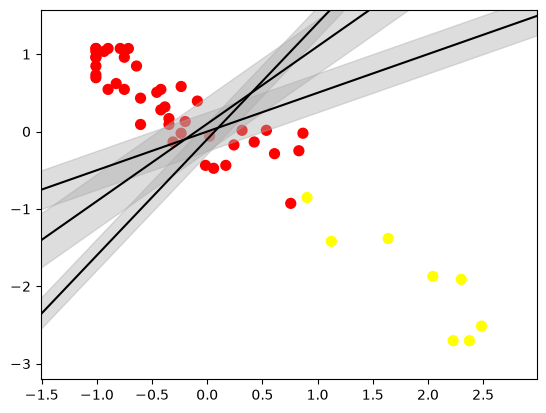

In [4]:
xfit = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(0.5, 0.0, 0.25), (1.0, 0.1, 0.35), (1.5, -0.1, 0.20)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
plt.ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
plt.show()

In [5]:
from sklearn.svm import SVC
model = SVC(kernel='linear', C=10.0)
model.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [6]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='black')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

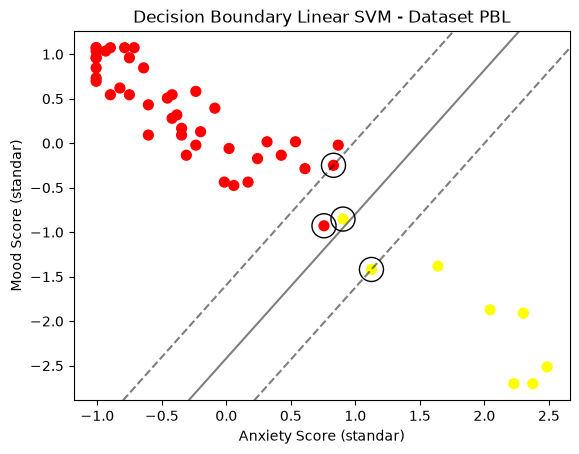

In [7]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.xlabel('Anxiety Score (standar)')
plt.ylabel('Mood Score (standar)')
plt.title('Decision Boundary Linear SVM - Dataset PBL')
plt.show()

In [8]:
model.support_vectors_

array([[ 0.8306167 , -0.24848709],
       [ 0.75704569, -0.928239  ],
       [ 0.90418771, -0.85271101],
       [ 1.12490074, -1.41917093]])

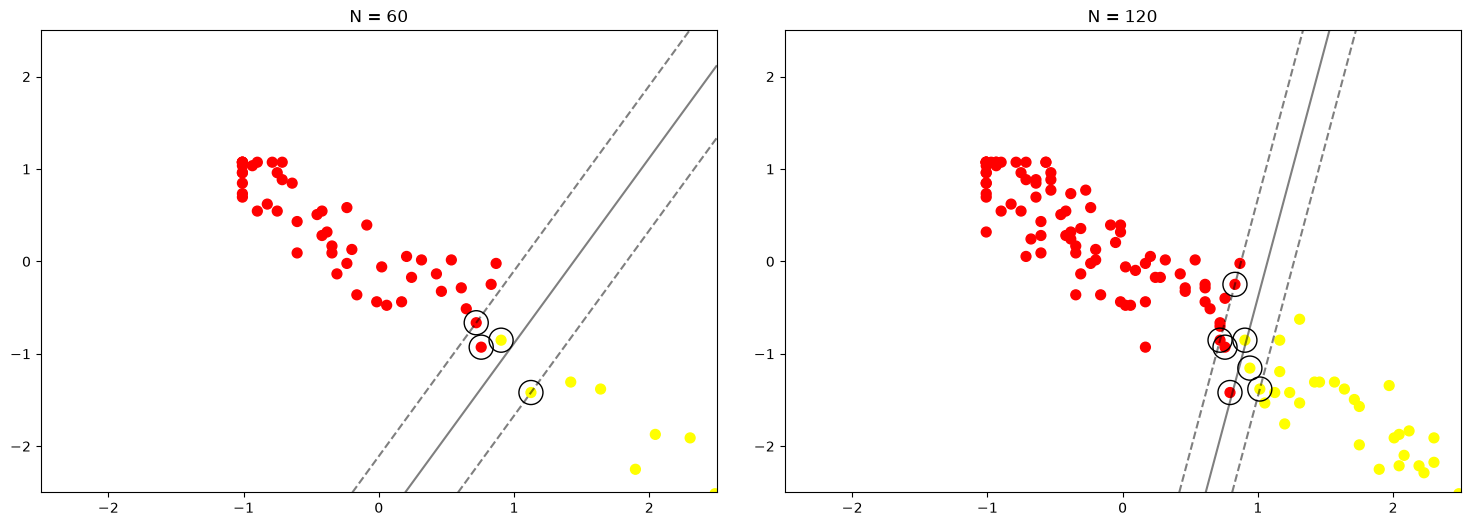

In [9]:
df_samp_200 = df_sub.sample(n=200, random_state=42)
X_200 = scaler.transform(df_samp_200[['Anxiety_Score', 'Mood_Score']].to_numpy())
y_200 = (df_samp_200['Burnout_Risk'] == 'High').astype(int).to_numpy()

def plot_svm(N=60, ax=None):
    X_n = X_200[:N]
    y_n = y_200[:N]
    model_n = SVC(kernel='linear', C=10.0)
    model_n.fit(X_n, y_n)

    ax = ax or plt.gca()
    ax.scatter(X_n[:, 0], X_n[:, 1], c=y_n, s=50, cmap='autumn')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    plot_svc_decision_function(model_n, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

In [10]:
from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=60, ax=None)>